### Problem 7: Quantum Nearest Neighbour(QNN)
Quantum Nearest Neighbor is a foundational algorithm in Quantum AI for quantum classification. It leverages the distance or similarity between quantum states to classify data points, which is analogous to the classical k-Nearest Neighbor algorithm.

**TASK :**

You will implement a basic QNN algorithm to compare quantum states and classify a new data point based on its similarity to a set of labeled quantum states.

**Scenario :**
1. Training States:
    - ∣q1⟩ : Label 0, corresponds to the data point x1=0.2
    - ∣q2⟩ : Label 1, corresponds to data point x2=0.8
2. Test State:
    - A new data point x_test=0.5

The goal is to classify x_test by determining which training state it is "closer" to using the SWAP test.

---

**APPROACH :**

The SWAP test is a quantum algorithm to compute the overlap (similarity) between two quantum states. Here's how it works:

1. Prepare two quantum states: the test state and a training state.
2. Add an ancilla qubit in the ∣+⟩ state.
3. Apply a controlled SWAP gate between the test state and the training state.
4. Measure the `ancilla` qubit. The measurement outcome gives the overlap.

**STEPS :**
1. Encode x1,x2,x_test using angle encoding.
2. Implement the SWAP test to compute overlaps.
3. Classify x_test based on the highest similarity.




In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
# from qiskit.visualization import plot_bloch_multivector
import numpy as np

In [2]:
# Function for Angle Encoding
def angle_encoding(x):
    qc = QuantumCircuit(1)
    qc.ry(2 * x, 0)  # Rotate the qubit by 2x radians on Y-axis
    return qc

#### What is Ancilla in qubits ?

- Imagine you're building a complex machine.
- You need some extra parts to help you assemble the main parts.
- These extra parts aren't part of the final machine, but they're crucial for the building process.

In quantum computing, these extra parts are called ancilla qubits.
They're like helper qubits that assist in performing quantum operations on the main qubits.
They might help create specific quantum states, implement certain quantum gates, or even correct errors.

Here are some key points about ancilla qubits:

* **Temporary:** They're not part of the final quantum state or the output of a quantum computation.
* **Versatile:** They can be used in various ways, depending on the specific quantum algorithm or operation.
* **Essential:** They often play a crucial role in enabling complex quantum computations.

Think of them as the behind-the-scenes workers of the quantum world, making the magic happen!

Read more about Ancilla qubits here - https://en.wikipedia.org/wiki/Ancilla_bit


In [3]:
# SWAP Test Implementation
def swap_test(test_state, train_state):
    qc = QuantumCircuit(3, 1)  # 3 qubits: 1 ancilla, 2 for states
    ancilla, q1, q2 = 0, 1, 2
    
    # Prepare ancilla in |+> state
    qc.h(ancilla)
    
    # Encode the test and training states
    qc.compose(test_state, qubits=[q1], inplace=True)
    qc.compose(train_state, qubits=[q2], inplace=True)
    
    # Apply controlled SWAP gate
    qc.cswap(ancilla, q1, q2)
    
    # Measure the ancilla
    qc.h(ancilla)
    qc.measure(ancilla, 0)
    return qc

#### What exactly does the SWAP test give us ?

For two single-qubit states ∣a⟩ and ∣b⟩, the probability of measuring the ancilla as ∣0⟩ is

**P(0) = ( 1 + |⟨a∣b⟩|² ) / 2**

so rearranging,

**|⟨a∣b⟩|² = 2·P(0) − 1**

Notice what this quantity is : it is the **fidelity**, i.e. the *squared* overlap - not ⟨a∣b⟩ itself.
It runs from 0 (orthogonal states) to 1 (identical states), and the SWAP test can never tell us the
sign or the phase of the overlap, only its magnitude squared.

Two practical points before we code it up :

1. `P(0)` is estimated from a finite number of shots, so the answer carries **statistical noise** of
   roughly 1/√shots. We must therefore pass `shots` explicitly and divide by that same number -
   dividing by a hard-coded value that does not match the run is a silent bug.
2. Because of that noise, the estimate can land slightly outside [0, 1]. We clip it.

In [4]:
# Simulate the SWAP test
def simulate_swap_test(test_state, train_state, shots=8192):
    qc = swap_test(test_state, train_state)
    simulator = Aer.get_backend('qasm_simulator')
    result = (simulator.run(transpile(qc, simulator), shots=shots)).result()
    counts = result.get_counts()

    prob_0 = counts.get('0', 0) / shots     # normalise by the SAME number of shots we ran
    fidelity = 2 * prob_0 - 1               # |<a|b>|^2
    return max(0.0, min(1.0, fidelity))     # clip away the shot-noise overshoot


In [5]:
# Prepare states
x1, x2, x_test = 0.2, 0.8, 0.5
train_state_1 = angle_encoding(x1)
train_state_2 = angle_encoding(x2)
test_state = angle_encoding(x_test)

In [6]:
# Compute fidelities (squared overlaps) with each class
fidelity_1 = simulate_swap_test(test_state, train_state_1)
fidelity_2 = simulate_swap_test(test_state, train_state_2)

# With angle encoding |x> = cos(x)|0> + sin(x)|1>, the exact answer is cos^2(x_a - x_b).
# Having the analytical value lets us see how much of the result is just shot noise.
exact_1 = np.cos(x_test - x1) ** 2
exact_2 = np.cos(x_test - x2) ** 2


In [7]:
# Classification based on maximum fidelity
# The two estimates are statistical, so anything closer than the shot noise is a TIE, not a winner.
tolerance = 3 / np.sqrt(8192)      # ~3 standard errors

if abs(fidelity_1 - fidelity_2) < tolerance:
    classification = "Tie - the test point is equidistant from both classes"
elif fidelity_1 > fidelity_2:
    classification = "Class 0"
else:
    classification = "Class 1"


In [8]:
# Print results
print(f"Fidelity with Class 0 (x1 = {x1}): {fidelity_1:.4f}   (exact: {exact_1:.4f})")
print(f"Fidelity with Class 1 (x2 = {x2}): {fidelity_2:.4f}   (exact: {exact_2:.4f})")
print(f"Difference: {abs(fidelity_1 - fidelity_2):.4f}  |  noise tolerance: {tolerance:.4f}")
print()
print(f"Test state x_test = {x_test} is classified as: {classification}")


Fidelity with Class 0 (x1 = 0.2): 0.9229   (exact: 0.9127)
Fidelity with Class 1 (x2 = 0.8): 0.9167   (exact: 0.9127)
Difference: 0.0061  |  noise tolerance: 0.0331

Test state x_test = 0.5 is classified as: Tie - the test point is equidistant from both classes


Since the SWAP test estimates the **fidelity** |⟨a∣b⟩|² between two quantum states -

- Fidelity close to 1 means the states are very similar, i.e. a small quantum "distance".
- Fidelity close to 0 means the states are nearly orthogonal.
- We classify the test point by whichever training state it overlaps with the most.

**But look at the numbers.** The exact values are

- cos²(0.5 − 0.2) = cos²(0.3) = **0.9127**
- cos²(0.5 − 0.8) = cos²(−0.3) = **0.9127**

They are *identical*. With this encoding x_test = 0.5 sits exactly halfway between x1 = 0.2 and
x2 = 0.8, so there is genuinely no nearest neighbour - it is a tie.

This is an important lesson : if we had simply compared two noisy estimates and declared a winner,
we would have "classified" the point on the strength of pure shot noise, and the answer would flip
from run to run. Whenever you compare estimated quantities, **compare the gap against the noise**.

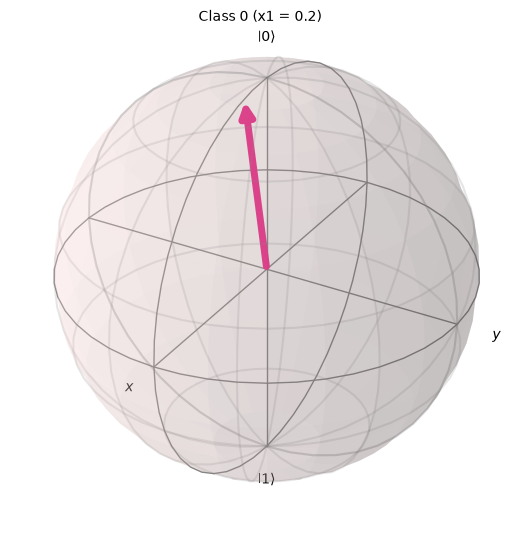

In [9]:
from qiskit.visualization import plot_bloch_vector
from math import cos, sin

# Define the states
def get_bloch_coords(angle_rad):
    """Convert an angle to Bloch sphere coordinates."""
    x = sin(angle_rad)  # sin(theta) component for |1>
    z = cos(angle_rad)  # cos(theta) component for |0>
    return [x, 0, z]  # y is 0 as the states lie in the X-Z plane

# Angles in radians
angle_x1 = 0.2  # Class 0
angle_x2 = 0.8  # Class 1
angle_xtest = 0.5  # Test state

# Bloch vectors
bloch_x1 = get_bloch_coords(angle_x1)
bloch_x2 = get_bloch_coords(angle_x2)
bloch_xtest = get_bloch_coords(angle_xtest)

# Plot the Bloch vectors
fig_x1 = plot_bloch_vector(bloch_x1, title="Class 0 (x1 = 0.2)")
fig_x2 = plot_bloch_vector(bloch_x2, title="Class 1 (x2 = 0.8)")
fig_xtest = plot_bloch_vector(bloch_xtest, title="Test State (x_test = 0.5)")

fig_x1


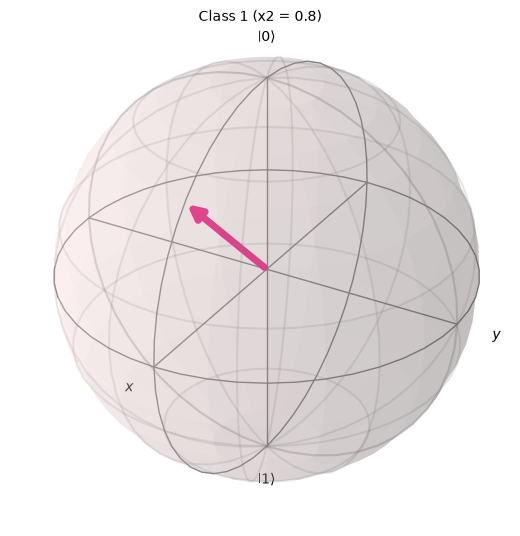

In [10]:
fig_x2

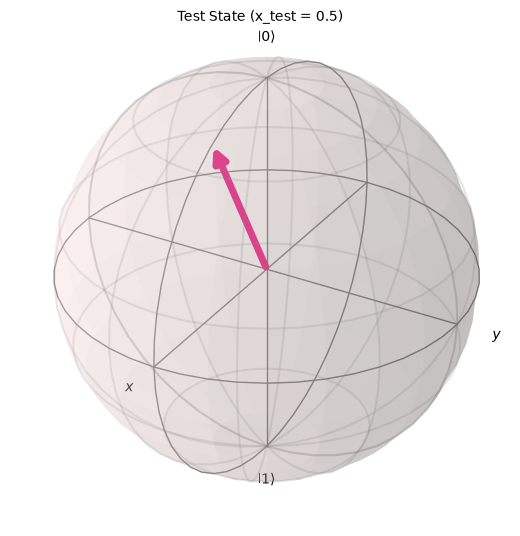

In [11]:
fig_xtest

#### TASK :
Introduce noise to this system and check how it deviates from the ideal predicted values.

----
#### A test point that really does have a nearest neighbour

Let us now try x_test = 0.35, which sits closer to x1 = 0.2 than to x2 = 0.8. This time the gap
should be far larger than the shot noise, and the classifier should be confident and stable.

In [12]:
def classify(x_test_value, shots=8192):
    """Run the full QNN pipeline for one test point and report the verdict."""
    test = angle_encoding(x_test_value)
    f1 = simulate_swap_test(test, train_state_1, shots)
    f2 = simulate_swap_test(test, train_state_2, shots)
    tol = 3 / np.sqrt(shots)

    if abs(f1 - f2) < tol:
        verdict = "Tie"
    else:
        verdict = "Class 0" if f1 > f2 else "Class 1"

    print(f"x_test = {x_test_value}")
    print(f"  fidelity vs Class 0 (x1={x1}): {f1:.4f}   (exact {np.cos(x_test_value - x1)**2:.4f})")
    print(f"  fidelity vs Class 1 (x2={x2}): {f2:.4f}   (exact {np.cos(x_test_value - x2)**2:.4f})")
    print(f"  gap {abs(f1 - f2):.4f} vs tolerance {tol:.4f}  ->  {verdict}")
    print()
    return verdict


classify(0.35)   # clearly Class 0
classify(0.65)   # clearly Class 1
classify(0.50)   # the tie from before


x_test = 0.35
  fidelity vs Class 0 (x1=0.2): 0.9778   (exact 0.9777)
  fidelity vs Class 1 (x2=0.8): 0.8130   (exact 0.8108)
  gap 0.1648 vs tolerance 0.0331  ->  Class 0

x_test = 0.65
  fidelity vs Class 0 (x1=0.2): 0.8042   (exact 0.8108)
  fidelity vs Class 1 (x2=0.8): 0.9797   (exact 0.9777)
  gap 0.1755 vs tolerance 0.0331  ->  Class 1

x_test = 0.5
  fidelity vs Class 0 (x1=0.2): 0.9141   (exact 0.9127)
  fidelity vs Class 1 (x2=0.8): 0.9199   (exact 0.9127)
  gap 0.0059 vs tolerance 0.0331  ->  Tie



'Tie'